# Zadatak 2: Cesticni filtar za pracenje mete

1) Simulacija trajektorije mete



In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

T = 50  

# stvarna trajektorija
mu = 2.0 ** (-np.arange(T) / 10)        
v_true = rng.normal(mu, mu / 3)          

x_true = np.zeros(T)
for t in range(T - 1):
    x_true[t + 1] = x_true[t] + v_true[t]

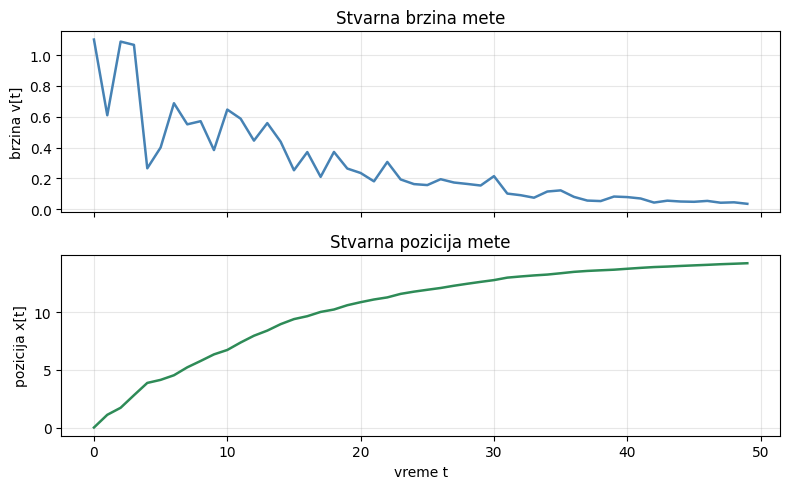

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)

axes[0].plot(np.arange(T), v_true, color='steelblue', linewidth=1.8)
axes[0].set_ylabel('brzina v[t]')
axes[0].set_title('Stvarna brzina mete')
axes[0].grid(alpha=0.3)

axes[1].plot(np.arange(T), x_true, color='seagreen', linewidth=1.8)
axes[1].set_xlabel('vreme t')
axes[1].set_ylabel('pozicija x[t]')
axes[1].set_title('Stvarna pozicija mete')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

2) Generisanje merenja

In [3]:
def laplace_scale(x):
    return np.sqrt(np.abs(x)) / 5 # Skaliranje b(x) = sqrt(|x|)/5

# Bernuli: 1 sa verovatnocom 0.9 (validno merenje), 0 inace
theta = (rng.random(T) < 0.9).astype(int)

# Laplaceov sum sa skalom b(x_true[t]), za x = 0 skala je 0, pa stavimo mali epsilon
b = laplace_scale(x_true)
b_safe = np.where(b > 0, b, 1e-6)
n = rng.laplace(loc=0.0, scale=b_safe)

# merenje
e = theta * x_true + n

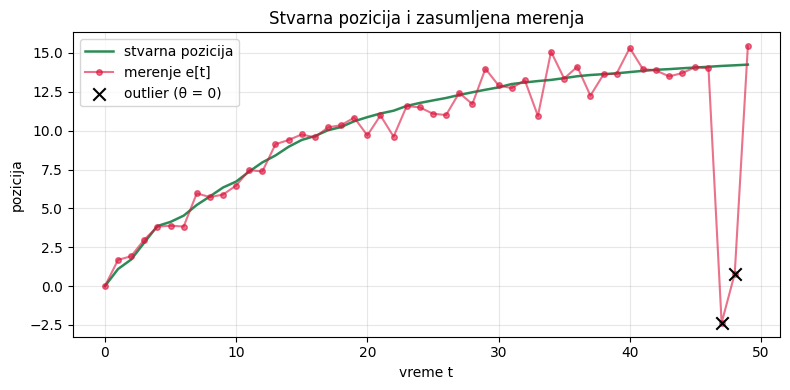

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(T), x_true, color='seagreen', linewidth=1.8, label='stvarna pozicija')
ax.plot(np.arange(T), e, 'o-', color='crimson', alpha=0.6, markersize=4, label='merenje e[t]')

outlier_idx = np.where(theta == 0)[0]
ax.scatter(outlier_idx, e[outlier_idx], color='black', marker='x', s=80,
           label='outlier (θ = 0)', zorder=5)

ax.set_xlabel('vreme t')
ax.set_ylabel('pozicija')
ax.set_title('Stvarna pozicija i zasumljena merenja')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

3) Cesticni filtar 

In [5]:
def laplace_pdf(z, b):
    b_safe = np.where(b > 0, b, 1e-6)
    return np.exp(-np.abs(z) / b_safe) / (2 * b_safe)

def measurement_likelihood(e_t, x_particles):
    b = laplace_scale(x_particles)
    # theta 1 i theta 0
    p_signal = laplace_pdf(e_t - x_particles, b)   
    p_noise  = laplace_pdf(e_t, b)                  
    return 0.9 * p_signal + 0.1 * p_noise

In [6]:
def particle_filter(e_obs, N_p, T, rng, resample_mode='always',
                    save_snapshots=None):
    
    x_particles = np.zeros(N_p)
    mu_0 = 2.0 ** 0  # = 1
    v_particles = rng.normal(mu_0, mu_0 / 3, size=N_p)
    weights = np.ones(N_p) / N_p

    x_est = np.zeros(T)
    v_est = np.zeros(T)
    snapshots = {}

    for t in range(T):
        # azuriranje tezina prema merenju e[t] 
        likelihood = measurement_likelihood(e_obs[t], x_particles)
        weights = weights * likelihood
        # ako je suma 0, reset na uniformne
        s = weights.sum()
        if s > 0:
            weights = weights / s
        else:
            weights = np.ones(N_p) / N_p

        # otezana srednja vrednost 
        x_est[t] = np.sum(weights * x_particles)
        v_est[t] = np.sum(weights * v_particles)

        if save_snapshots is not None and t in save_snapshots:
            snapshots[t] = (x_particles.copy(), v_particles.copy(), weights.copy())

        # reuzorkvanje
        do_resample = False
        if resample_mode == 'always':
            do_resample = True
        elif resample_mode == 'conditional':
            N_eff = 1.0 / np.sum(weights ** 2)
            if N_eff < N_p / 2:
                do_resample = True

        if do_resample:
            indices = rng.choice(N_p, size=N_p, p=weights)
            x_particles = x_particles[indices]
            v_particles = v_particles[indices]
            weights = np.ones(N_p) / N_p

        # predikcija
        if t < T - 1:
            mu_t = 2.0 ** (-(t + 1) / 10)  
            v_particles = rng.normal(mu_t, mu_t / 3, size=N_p)
            x_particles = x_particles + v_particles

    return x_est, v_est, snapshots

In [7]:
N_p = 1000

x_est, v_est, _ = particle_filter(e, N_p, T, rng, resample_mode='always')

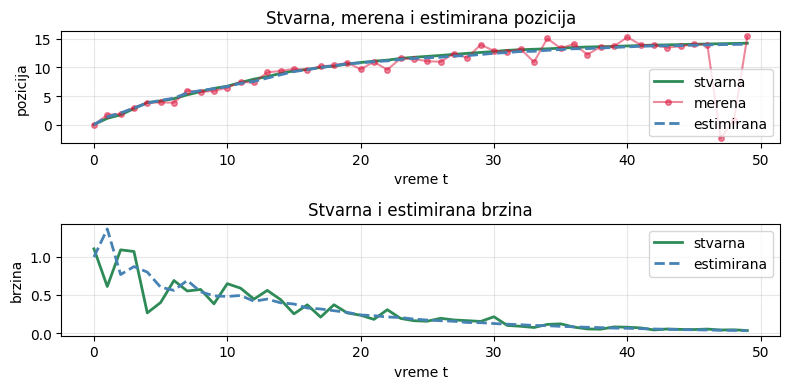

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(8, 4))

axes[0].plot(np.arange(T), x_true, color='seagreen', linewidth=2, label='stvarna')
axes[0].plot(np.arange(T), e, 'o-', color='crimson', alpha=0.5,
             markersize=4, label='merena')
axes[0].plot(np.arange(T), x_est, color='steelblue', linewidth=2,
             linestyle='--', label='estimirana')
axes[0].set_xlabel('vreme t')
axes[0].set_ylabel('pozicija')
axes[0].set_title('Stvarna, merena i estimirana pozicija')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(np.arange(T), v_true, color='seagreen', linewidth=2, label='stvarna')
axes[1].plot(np.arange(T), v_est, color='steelblue', linewidth=2,
             linestyle='--', label='estimirana')
axes[1].set_xlabel('vreme t')
axes[1].set_ylabel('brzina')
axes[1].set_title('Stvarna i estimirana brzina')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

4) Vizualizacija cestica

In [9]:
# outlieri
outlier_times = np.where(theta == 0)[0]
print(f"Outlieri su u trenucima: {outlier_times}")

snapshot_times = sorted([3, int(outlier_times[0]), int(outlier_times[len(outlier_times)//2]), 45])
print(f"Snapshot trenuci: {snapshot_times}")

rng_snap = np.random.default_rng(123)  
x_est_snap, v_est_snap, snapshots = particle_filter(
    e, N_p, T, rng_snap, resample_mode='always',
    save_snapshots=snapshot_times
)

Outlieri su u trenucima: [47 48]
Snapshot trenuci: [3, 45, 47, 48]


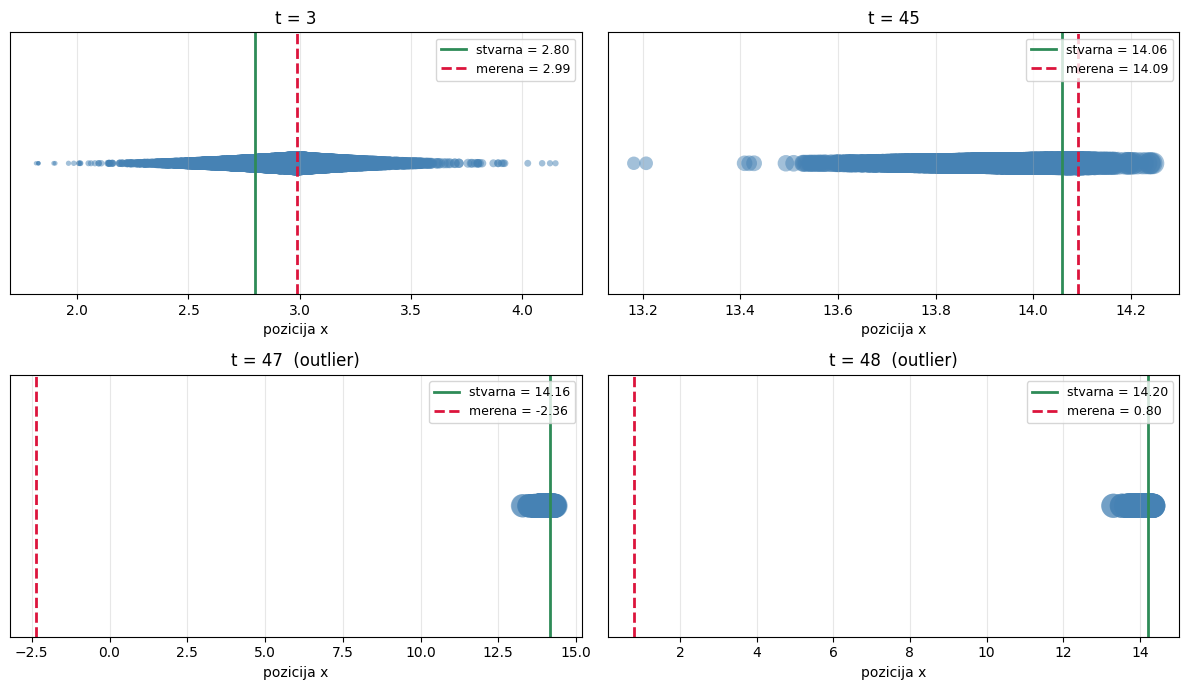

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes = axes.flatten()

for ax, t in zip(axes, snapshot_times):
    x_p, v_p, w = snapshots[t]
    
    w_norm = w / w.max()
    marker_sizes = 5 + 300 * w_norm  
    
    order = np.argsort(w)
    
    ax.scatter(x_p[order], np.zeros_like(x_p[order]),
               s=marker_sizes[order],
               color='steelblue', alpha=0.5, edgecolors='none')
    ax.axvline(x_true[t], color='seagreen', linewidth=2,
               label=f'stvarna = {x_true[t]:.2f}')
    ax.axvline(e[t], color='crimson', linewidth=2, linestyle='--',
               label=f'merena = {e[t]:.2f}')
    
    is_outlier = theta[t] == 0
    title = f't = {t}'
    if is_outlier:
        title += '  (outlier)'
    ax.set_title(title)
    ax.set_xlabel('pozicija x')
    ax.set_yticks([])
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

5) Monte Carlo

In [11]:
def one_mc_simulation(N_p, T, rng, resample_mode):

    # stvarna trajektorija
    mu = 2.0 ** (-np.arange(T) / 10)
    v_t = rng.normal(mu, mu / 3)
    x_t = np.zeros(T)
    for t in range(T - 1):
        x_t[t + 1] = x_t[t] + v_t[t]

    # merenja
    theta_t = (rng.random(T) < 0.9).astype(int)
    b_t = laplace_scale(x_t)
    b_safe_t = np.where(b_t > 0, b_t, 1e-6)
    n_t = rng.laplace(loc=0.0, scale=b_safe_t)
    e_t = theta_t * x_t + n_t

    x_est, _, _ = particle_filter(e_t, N_p, T, rng, resample_mode=resample_mode)

    rmse = np.sqrt(np.mean((x_est - x_t) ** 2))
    return rmse

In [12]:
N_mc = 500
N_p_mc = 1000  

rmse_never = np.zeros(N_mc)
rmse_always = np.zeros(N_mc)
rmse_conditional = np.zeros(N_mc)

rng_mc = np.random.default_rng(2024)

for i in range(N_mc):
    rmse_never[i]       = one_mc_simulation(N_p_mc, T, rng_mc, 'never')
    rmse_always[i]      = one_mc_simulation(N_p_mc, T, rng_mc, 'always')
    rmse_conditional[i] = one_mc_simulation(N_p_mc, T, rng_mc, 'conditional')
    

print("\nRezultati (RMSE pozicije):")
print(f"  Bez reuzorkovanja:        srednja vrednost = {rmse_never.mean():.4f},  std = {rmse_never.std():.4f}")
print(f"  U svakoj iteraciji:       srednja vrednost = {rmse_always.mean():.4f},  std = {rmse_always.std():.4f}")
print(f"  Uslovno (N_eff < N/2):    srednja vrednost = {rmse_conditional.mean():.4f},  std = {rmse_conditional.std():.4f}")


Rezultati (RMSE pozicije):
  Bez reuzorkovanja:        srednja vrednost = 0.2862,  std = 0.1204
  U svakoj iteraciji:       srednja vrednost = 0.2720,  std = 0.0926
  Uslovno (N_eff < N/2):    srednja vrednost = 0.2707,  std = 0.0941


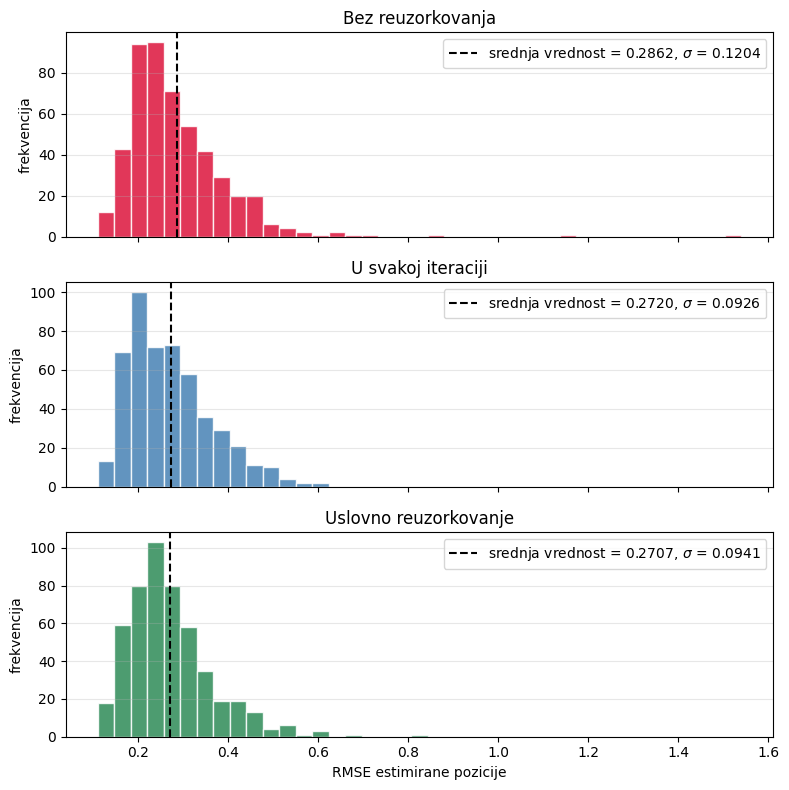

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(8, 8), sharex=True)

all_rmse = np.concatenate([rmse_never, rmse_always, rmse_conditional])
bins = np.linspace(all_rmse.min(), all_rmse.max(), 40)

strategies = [
    ('Bez reuzorkovanja',           rmse_never,       'crimson'),
    ('U svakoj iteraciji',          rmse_always,      'steelblue'),
    ('Uslovno reuzorkovanje',       rmse_conditional, 'seagreen'),
]

for ax, (name, rmse, color) in zip(axes, strategies):
    ax.hist(rmse, bins=bins, color=color, edgecolor='white', alpha=0.85)
    mean = rmse.mean()
    std = rmse.std()
    ax.axvline(mean, color='black', linestyle='--', linewidth=1.5,
               label=f'srednja vrednost = {mean:.4f}, $\\sigma$ = {std:.4f}')
    ax.set_ylabel('frekvencija')
    ax.set_title(name)
    ax.legend(loc='upper right')
    ax.grid(alpha=0.3, axis='y')

axes[-1].set_xlabel('RMSE estimirane pozicije')
plt.tight_layout()
plt.show()